In [28]:
data_path = '/data_pool/data/pollux202610/focused_beam_scan_module711_W17_5entance_1h_1v_300V_minus20_10us_hg0_780eV_group0'

start_index = 20

plot_samples = 9
plot_rows = 3
plot_columns = 3

vmin = -500
vmax = 2.5e6
im_norm = 'linear'

In [2]:
from pathlib import Path
from aare import RawFile
import numpy as np
import matplotlib.pyplot as plt
import os
import scipy

In [3]:
def extract_xy(filename):
    splitting = filename.split('_')
    x = splitting[0].split(':')[1]
    y = splitting[1].split(':')[1]
    # print(filename)
    return (int(x),int(y))

In [4]:
base = Path(data_path)
files = os.listdir(base)
data_files = [f for f in files if f.endswith('.json')]

In [5]:
for filename in data_files:
    if 'dark' in filename:
        print(f' found pedestal file: {filename}')
        pedestal_file = filename
        data_files.remove(pedestal_file)
        print(f'removed pedestal file: {filename} from data_files')

 found pedestal file: dark_master_1184.json
removed pedestal file: dark_master_1184.json from data_files


In [6]:
sorted_files = sorted(data_files, key=extract_xy)

In [7]:
f = RawFile(base / data_files[0])
R = 1
headers, data = f.read()
del headers
# data has an ROI
len_y = data.shape[2]
len_x = data.shape[1]
# print(data.shape)
del data

In [17]:
pedestal = np.empty((len_x, len_y))
with RawFile(base / pedestal_file, chunk_size=10000000) as f:
    for i, (header, data) in enumerate(f):
        print(i)
        del header
        pedestal = np.mean(data, axis=0)

0


In [9]:
# index = sorted_files.index('x:3776_y:514_slits:2_energy:780_master_330.json')
# print(sorted_files[index])

In [34]:
total_images = np.zeros((plot_samples, len_x, len_y))
plot_file = [None] * plot_samples
for i in range(plot_samples):
    cur_filename = sorted_files[start_index + i]
    f = RawFile(base / cur_filename)
    plot_file[i] = cur_filename
    headers, data = f.read()
    del headers
    gain_data = data >> 14
    corrected_data = data - pedestal
    # corrected_data[gain_data > 0] = 0.0
    total_images[i] = np.sum(corrected_data, axis=0)
    del corrected_data

In [31]:
(gain_data > 0).sum()

np.int64(5753415)

In [11]:
def create_title(filename):
    pieces = filename.split('_')
    x_str = pieces[0]
    y_str = pieces[1]
    energy_str = pieces[2]
    no_str = pieces[4].split('.')[0]
    return f'{x_str}, {y_str}\n{energy_str} no. {no_str}'
create_title(cur_filename)

'x:-1240, y:-1498\nenergy:780 no. 1297'

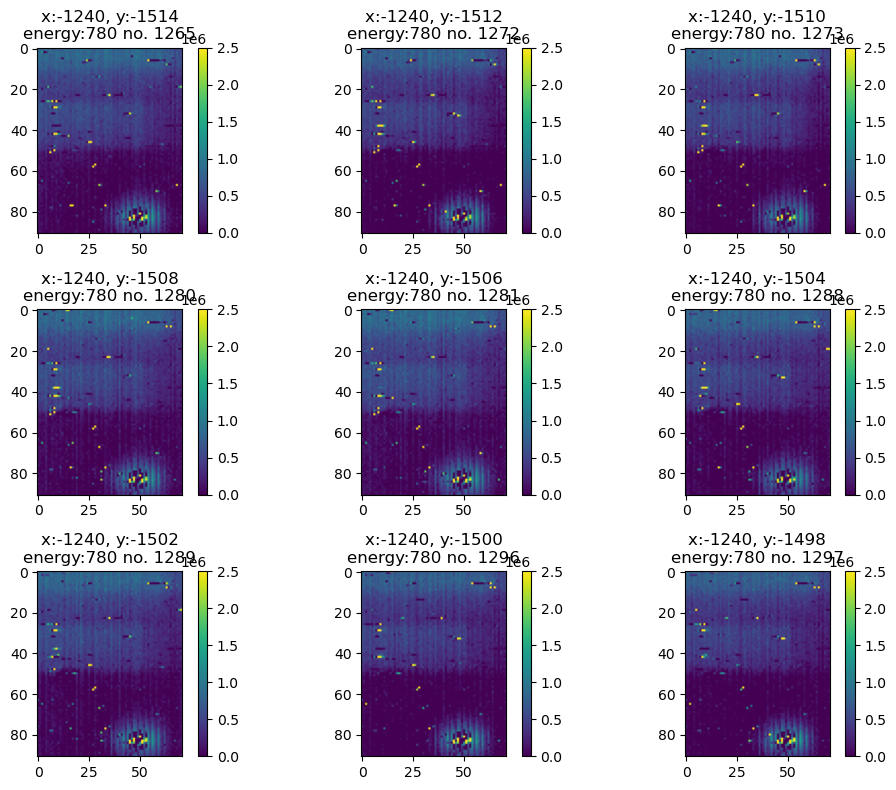

In [35]:
fig, axs = plt.subplots(plot_rows, plot_columns, figsize=(10, 8))
flat_axs = axs.flatten()
for i in range(plot_samples):
    cur_ax = flat_axs[i]
    cur_image = cur_ax.imshow(total_images[i], vmin=vmin, vmax=vmax, norm=im_norm)
    plt.colorbar(cur_image, ax=cur_ax)
    cur_ax.set_title(create_title(plot_file[i]))
fig.tight_layout()